# Brownian motion and covariance matrices

For isotropic diffusion,
$d\mathbf R_t=\sqrt{2D}I_d\,d\mathbf W_t$ and
$\operatorname{Cov}(\mathbf R_t)=2DtI_d$. The matrix calculation makes
independence and isotropy directly testable.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Simulation

Euler–Maruyama generates path ensembles in one, two, and three dimensions.
Only selected paths are retained for visualization; all paths contribute to
the empirical covariance matrices.


In [2]:
rng = np.random.default_rng(62703)
diffusivity = 0.45
time_step = 0.01
step_count = 600
path_count = 16_000
shown_path_count = 8
time = time_step * np.arange(step_count + 1)
results = {}

for dimension in (1, 2, 3):
    position = np.zeros((path_count, dimension))
    shown_paths = np.zeros((step_count + 1, shown_path_count, dimension))
    for step in range(1, step_count + 1):
        normal_vector = rng.standard_normal((path_count, dimension))
        position += np.sqrt(2.0 * diffusivity * time_step) * normal_vector
        shown_paths[step] = position[:shown_path_count]
    results[dimension] = {
        "paths": shown_paths,
        "covariance": np.cov(position, rowvar=False, ddof=0),
        "endpoint": position,
    }


## Verification

The normalized covariance should equal the identity matrix. Off-diagonal
entries test independence; diagonal entries test equal diffusivity.


In [3]:
final_time = time[-1]
normalized_covariance = {}
for dimension in (1, 2, 3):
    covariance = np.atleast_2d(results[dimension]["covariance"])
    normalized = covariance / (2.0 * diffusivity * final_time)
    normalized_covariance[dimension] = normalized
    assert np.allclose(normalized, np.eye(dimension), atol=0.035)
    print(f"{dimension}D normalized covariance:")
    print(normalized)


1D normalized covariance:
[[0.97915721]]
2D normalized covariance:
[[ 1.01544594 -0.01459987]
 [-0.01459987  1.01217189]]
3D normalized covariance:
[[ 1.00811984  0.00755494  0.00760047]
 [ 0.00755494  0.99814629 -0.0161221 ]
 [ 0.00760047 -0.0161221   1.00232514]]


## Instructive plot

The path panels show geometric dimensionality. The final panel places the
normalized empirical covariance matrices beside the identity-matrix target.


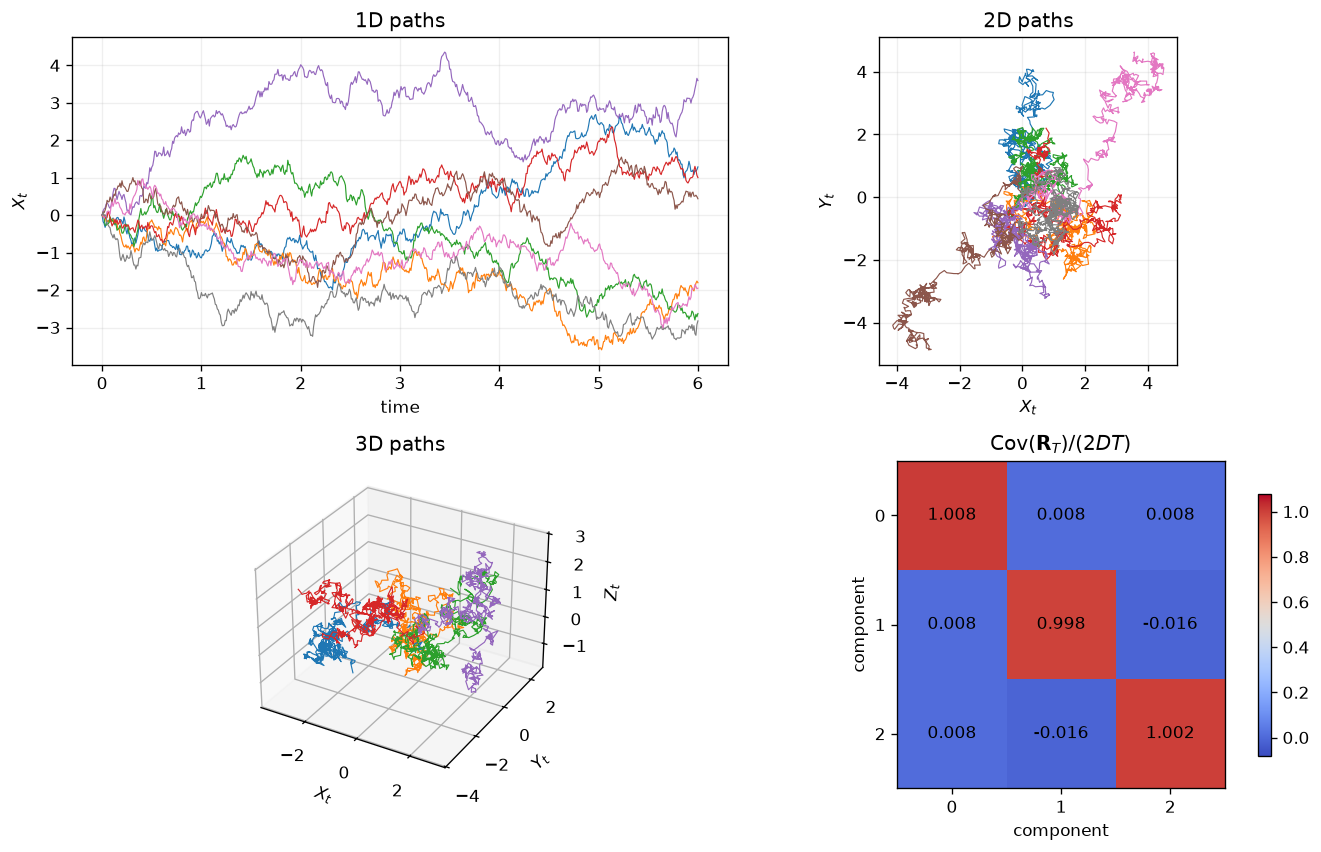

wrote lecture-notes/figures/08_brownian-motion-diffusion/03-brownian-motion-matrix-covariance.pdf


In [4]:
figure = plt.figure(figsize=(11.5, 7.2))
axis_1d = figure.add_subplot(2, 2, 1)
axis_2d = figure.add_subplot(2, 2, 2)
axis_3d = figure.add_subplot(2, 2, 3, projection="3d")
axis_covariance = figure.add_subplot(2, 2, 4)

axis_1d.plot(time, results[1]["paths"][:, :, 0], linewidth=0.7)
axis_1d.set(title="1D paths", xlabel="time", ylabel=r"$X_t$")

paths_2d = results[2]["paths"]
for path_index in range(shown_path_count):
    axis_2d.plot(paths_2d[:, path_index, 0], paths_2d[:, path_index, 1], linewidth=0.7)
axis_2d.set(title="2D paths", xlabel=r"$X_t$", ylabel=r"$Y_t$")
axis_2d.set_aspect("equal", adjustable="box")

paths_3d = results[3]["paths"]
for path_index in range(5):
    axis_3d.plot(
        paths_3d[:, path_index, 0],
        paths_3d[:, path_index, 1],
        paths_3d[:, path_index, 2],
        linewidth=0.7,
    )
axis_3d.set(title="3D paths", xlabel=r"$X_t$", ylabel=r"$Y_t$", zlabel=r"$Z_t$")

covariance_image = axis_covariance.imshow(
    normalized_covariance[3], vmin=-0.08, vmax=1.08, cmap="coolwarm"
)
for row in range(3):
    for column in range(3):
        axis_covariance.text(
            column,
            row,
            f"{normalized_covariance[3][row, column]:.3f}",
            ha="center",
            va="center",
        )
axis_covariance.set(
    title=r"$\operatorname{Cov}(\mathbf{R}_T)/(2DT)$",
    xticks=range(3),
    yticks=range(3),
    xlabel="component",
    ylabel="component",
)
figure.colorbar(covariance_image, ax=axis_covariance, shrink=0.8)

for axis in (axis_1d, axis_2d):
    axis.grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "03-brownian-motion-matrix-covariance.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
